# **MDP (Markov Decision Process)= évaluer le comportement et la valeur business**

| Élément      | Dans LE  projet                                       |
| ------------ | ----------------------------------------------------- |
| États S      | Browsing, Engaged, HighIntent                         |
| Actions A    | pub, promo, rec                                       |
| Transition P | probabilité de passer vers un autre état après action |
| Récompense R | gain obtenu après action                              |
| Politique π  | meilleure action pour chaque état                     |


In [1]:
!pip install pandas numpy scipy matplotlib seaborn tqdm

In [5]:
from google.colab import drive
drive.mount('/content/drive')
CLICKS_PATH = "/content/drive/MyDrive/proj_indiv/data/yoochoose-data/yoochoose-clicks.dat"

BUYS_PATH = "/content/drive/MyDrive/proj_indiv/data/yoochoose-data/yoochoose-buys.dat"

Mounted at /content/drive


In [6]:
# ============================================================
# RELOAD CLICKS FOR HMM
# ============================================================

import pandas as pd

CLICKS_PATH = "/content/drive/MyDrive/proj_indiv/data/yoochoose-data/yoochoose-clicks.dat"

print("Chargement clicks...")

clicks = pd.read_csv(
    CLICKS_PATH,
    header=None,
    names=["session_id", "timestamp", "item_id", "category"],
    dtype={
        "session_id": "int64",
        "item_id": "string",
        "category": "string"
    },
    low_memory=False
)

# timestamps
clicks["timestamp"] = pd.to_datetime(
    clicks["timestamp"],
    errors="coerce",
    utc=True
)

clicks = clicks.dropna(subset=["timestamp"])

# ============================================================
# SAMPLE 100000 SESSIONS
# ============================================================

sessions = clicks["session_id"].unique()[:100000]

clicks = clicks[
    clicks["session_id"].isin(sessions)
]

print("Clicks shape:", clicks.shape)

clicks.head()

Chargement clicks...
Clicks shape: (395698, 4)


,session_id,timestamp,item_id,category
0,1,2014-04-07 10:51:09.277000+00:00,214536502,0
1,1,2014-04-07 10:54:09.868000+00:00,214536500,0
2,1,2014-04-07 10:54:46.998000+00:00,214536506,0
3,1,2014-04-07 10:57:00.306000+00:00,214577561,0
4,2,2014-04-07 13:56:37.614000+00:00,214662742,0


**Les séquences d'états**

In [26]:
# ============================================================
# Recréer les observations O_t pour MDP
# ============================================================

clicks = clicks.sort_values(["session_id", "timestamp"]).copy()

# rang du clic dans la session
clicks["rank"] = clicks.groupby("session_id").cumcount() + 1

# temps entre clics
clicks["dt"] = clicks.groupby("session_id")["timestamp"].diff().dt.total_seconds()

def activity_state(rank):
    if rank <= 2:
        return "Low"
    elif rank <= 5:
        return "Medium"
    else:
        return "High"

def speed_state(dt):
    if pd.isna(dt):
        return "Normal"
    elif dt <= 50:
        return "Fast"
    elif dt <= 200:
        return "Normal"
    else:
        return "Slow"

clicks["obs_activity"] = clicks["rank"].apply(activity_state)
clicks["obs_speed"] = clicks["dt"].apply(speed_state)

clicks["O_t"] = clicks["obs_activity"] + "_" + clicks["obs_speed"]

print(clicks[["session_id", "rank", "dt", "O_t"]].head(10))

   session_id  rank       dt            O_t
0           1     1      NaN     Low_Normal
1           1     2  180.591     Low_Normal
2           1     3   37.130    Medium_Fast
3           1     4  133.308  Medium_Normal
4           2     1      NaN     Low_Normal
5           2     2   41.759       Low_Fast
6           2     3   78.073  Medium_Normal
7           2     4   73.264  Medium_Normal
8           2     5   47.537    Medium_Fast
9           2     6  118.642    High_Normal


Le tableau obtenu représente la transformation des données brutes de navigation en états observables utilisés dans le modèle HMM/MDP. Chaque ligne correspond à une interaction utilisateur dans une session e-commerce.

La colonne rank indique la position du clic dans la session utilisateur. Cette information permet de mesurer le niveau d’engagement progressif de l’utilisateur au cours de sa navigation.

La colonne dt représente le temps écoulé entre deux clics consécutifs, exprimé en secondes. Cette variable permet d’estimer la vitesse de navigation de l’utilisateur.

À partir de ces deux informations, une discrétisation comportementale a été réalisée afin de construire les observations O_t utilisées dans le HMM et le MDP.

Le niveau d’activité est défini selon le rang du clic :
- Low : faible engagement (1 à 2 clics),
- Medium : engagement intermédiaire (3 à 5 clics),
- High : fort engagement (plus de 5 clics).

La vitesse de navigation est définie à partir du temps dt :
- Fast : navigation rapide,
- Normal : navigation modérée,
- Slow : navigation lente.

L’observation finale O_t combine ces deux dimensions comportementales. Par exemple :
- Low_Normal correspond à un utilisateur peu engagé avec une vitesse de navigation normale ;
- Medium_Fast correspond à un utilisateur montrant un engagement moyen avec des clics rapides ;
- High_Normal représente un utilisateur fortement engagé avec une vitesse de navigation stable.

Cette discrétisation permet de transformer les données continues et hétérogènes du dataset YooChoose en un ensemble fini d’états observables exploitables par les modèles probabilistes et décisionnels du projet.

**Construire P_data = P(s'|s)**

**Visualiser P_data**

In [30]:
# ============================================================
# PREPARATION MDP
# ============================================================

import pandas as pd
import numpy as np

# ============================================================
# Trier données
# ============================================================

clicks = clicks.sort_values(
    ["session_id", "timestamp"]
).copy()

# ============================================================
# Rang dans session
# ============================================================

clicks["rank"] = (
    clicks.groupby("session_id")
    .cumcount() + 1
)

# ============================================================
# Temps entre clics
# ============================================================

clicks["dt"] = (
    clicks.groupby("session_id")["timestamp"]
    .diff()
    .dt.total_seconds()
)

# ============================================================
# Discrétisation activité
# ============================================================

def activity_state(rank):

    if rank <= 2:
        return "Low"

    elif rank <= 5:
        return "Medium"

    else:
        return "High"

# ============================================================
# Discrétisation vitesse
# ============================================================

def speed_state(dt):

    if pd.isna(dt):
        return "Normal"

    elif dt <= 50:
        return "Fast"

    elif dt <= 200:
        return "Normal"

    else:
        return "Slow"

# ============================================================
# Construire O_t
# ============================================================

clicks["obs_activity"] = (
    clicks["rank"]
    .apply(activity_state)
)

clicks["obs_speed"] = (
    clicks["dt"]
    .apply(speed_state)
)

clicks["O_t"] = (
    clicks["obs_activity"]
    + "_"
    + clicks["obs_speed"]
)

# ============================================================
# Construire séquences MDP
# ============================================================

state_sequences_mdp = (
    clicks.groupby("session_id")["O_t"]
    .apply(list)
    .tolist()
)

print("Nombre de séquences MDP:")
print(len(state_sequences_mdp))

print("\nExemple:")
print(state_sequences_mdp[0])

print("\nAperçu:")
print(
    clicks[
        ["session_id", "rank", "dt", "O_t"]
    ].head(10)
)

Nombre de séquences MDP:
100000

Exemple:
['Low_Normal', 'Low_Normal', 'Medium_Fast', 'Medium_Normal']

Aperçu:
   session_id  rank       dt            O_t
0           1     1      NaN     Low_Normal
1           1     2  180.591     Low_Normal
2           1     3   37.130    Medium_Fast
3           1     4  133.308  Medium_Normal
4           2     1      NaN     Low_Normal
5           2     2   41.759       Low_Fast
6           2     3   78.073  Medium_Normal
7           2     4   73.264  Medium_Normal
8           2     5   47.537    Medium_Fast
9           2     6  118.642    High_Normal


In [31]:
# ============================================================
# RECONSTRUIRE P_data
# ============================================================

import pandas as pd
import numpy as np

mdp_states = [
    "Low_Fast", "Low_Normal", "Low_Slow",
    "Medium_Fast", "Medium_Normal", "Medium_Slow",
    "High_Fast", "High_Normal", "High_Slow"
]

# matrice comptages
P_counts = pd.DataFrame(
    0,
    index=mdp_states,
    columns=mdp_states,
    dtype=float
)

# compter transitions
for seq in state_sequences_mdp:

    for t in range(len(seq) - 1):

        s = seq[t]
        s_next = seq[t + 1]

        if s in mdp_states and s_next in mdp_states:
            P_counts.loc[s, s_next] += 1

# lissage Laplace
alpha = 1.0

P_data = (P_counts + alpha).div(
    (P_counts + alpha).sum(axis=1),
    axis=0
)

print("=== P_data ===")
print(P_data.round(3))

=== P_data ===
               Low_Fast  Low_Normal  Low_Slow  Medium_Fast  Medium_Normal  \
Low_Fast           0.00       0.000     0.000        0.533          0.350   
Low_Normal         0.34       0.332     0.135        0.075          0.086   
Low_Slow           0.00       0.000     0.000        0.328          0.432   
Medium_Fast        0.00       0.000     0.000        0.439          0.244   
Medium_Normal      0.00       0.000     0.000        0.336          0.327   
Medium_Slow        0.00       0.000     0.000        0.291          0.322   
High_Fast          0.00       0.000     0.000        0.000          0.000   
High_Normal        0.00       0.000     0.000        0.000          0.000   
High_Slow          0.00       0.000     0.000        0.000          0.000   

               Medium_Slow  High_Fast  High_Normal  High_Slow  
Low_Fast             0.117      0.000        0.000      0.000  
Low_Normal           0.031      0.000        0.000      0.000  
Low_Slow             0

**Interprétation:**

Cette matrice représente les transitions naturelles sans action marketing.

1. États Low

Depuis Low_Fast :

53.3% → Medium_Fast
35.0% → Medium_Normal
11.7% → Medium_Slow

Donc un utilisateur rapide au début progresse souvent vers Medium.

Depuis Low_Normal :

34.0% → Low_Fast
33.2% → Low_Normal
13.5% → Low_Slow

Donc beaucoup restent encore dans la phase Low.

2. États Medium

Depuis Medium_Fast :

43.9% → Medium_Fast
14.3% → High_Fast
7.2% → High_Normal
2.4% → High_Slow

La transition vers High existe, mais elle reste limitée.
C’est le bottleneck du funnel.

3. États High

Depuis High_Fast :

62.6% → High_Fast
28.7% → High_Normal
8.7% → High_Slow

Les utilisateurs restent surtout dans High.
Donc High est un état stable de forte intention.

La matrice P_data confirme une structure de funnel :
Low → Medium → High.
La progression Low vers Medium est relativement fréquente, mais le passage Medium vers High reste plus difficile. Cela justifie l’introduction d’actions marketing dans le MDP : publicité pour stimuler Low, promotion pour débloquer Medium, et recommandation pour stabiliser High.

### **construire P(s'|s,a) avec les actions:**

In [32]:
# ============================================================
# Construire P(s' | s, a)
# Actions : nothing, pub, promo, rec
# ============================================================

import copy
import pandas as pd
import numpy as np

actions = ["nothing", "pub", "promo", "rec"]

def normalize_rows(df):
    df = df.clip(lower=0)  # éviter valeurs négatives
    return df.div(df.sum(axis=1), axis=0).fillna(0)

def build_P_actions(P_data):
    P_actions = {}

    # 1) nothing = comportement naturel
    P_actions["nothing"] = P_data.copy()

    # 2) pub : pousser Low -> Medium
    P_pub = P_data.copy()

    for s in mdp_states:
        if s.startswith("Low"):
            medium_cols = [c for c in mdp_states if c.startswith("Medium")]
            low_cols = [c for c in mdp_states if c.startswith("Low")]

            P_pub.loc[s, medium_cols] += 0.08
            P_pub.loc[s, low_cols] -= 0.08

    P_actions["pub"] = normalize_rows(P_pub)

    # 3) promo : pousser Medium -> High
    P_promo = P_data.copy()

    for s in mdp_states:
        if s.startswith("Medium"):
            high_cols = [c for c in mdp_states if c.startswith("High")]
            medium_cols = [c for c in mdp_states if c.startswith("Medium")]

            P_promo.loc[s, high_cols] += 0.10
            P_promo.loc[s, medium_cols] -= 0.10

    P_actions["promo"] = normalize_rows(P_promo)

    # 4) rec : stabiliser High
    P_rec = P_data.copy()

    for s in mdp_states:
        if s.startswith("High"):
            high_cols = [c for c in mdp_states if c.startswith("High")]

            P_rec.loc[s, high_cols] += 0.05

    P_actions["rec"] = normalize_rows(P_rec)

    return P_actions

P_actions = build_P_actions(P_data)

print("Actions disponibles:", list(P_actions.keys()))

for a in actions:
    print(f"\n=== Action: {a} ===")
    print(P_actions[a].round(3))

Actions disponibles: ['nothing', 'pub', 'promo', 'rec']

=== Action: nothing ===
               Low_Fast  Low_Normal  Low_Slow  Medium_Fast  Medium_Normal  \
Low_Fast           0.00       0.000     0.000        0.533          0.350   
Low_Normal         0.34       0.332     0.135        0.075          0.086   
Low_Slow           0.00       0.000     0.000        0.328          0.432   
Medium_Fast        0.00       0.000     0.000        0.439          0.244   
Medium_Normal      0.00       0.000     0.000        0.336          0.327   
Medium_Slow        0.00       0.000     0.000        0.291          0.322   
High_Fast          0.00       0.000     0.000        0.000          0.000   
High_Normal        0.00       0.000     0.000        0.000          0.000   
High_Slow          0.00       0.000     0.000        0.000          0.000   

               Medium_Slow  High_Fast  High_Normal  High_Slow  
Low_Fast             0.117      0.000        0.000      0.000  
Low_Normal          

In [33]:
# ============================================================
# Validation : chaque ligne doit sommer à 1
# ============================================================

for a in actions:
    print(f"\nSomme des lignes pour action = {a}")
    print(P_actions[a].sum(axis=1).round(6))


Somme des lignes pour action = nothing
Low_Fast         1.0
Low_Normal       1.0
Low_Slow         1.0
Medium_Fast      1.0
Medium_Normal    1.0
Medium_Slow      1.0
High_Fast        1.0
High_Normal      1.0
High_Slow        1.0
dtype: float64

Somme des lignes pour action = pub
Low_Fast         1.0
Low_Normal       1.0
Low_Slow         1.0
Medium_Fast      1.0
Medium_Normal    1.0
Medium_Slow      1.0
High_Fast        1.0
High_Normal      1.0
High_Slow        1.0
dtype: float64

Somme des lignes pour action = promo
Low_Fast         1.0
Low_Normal       1.0
Low_Slow         1.0
Medium_Fast      1.0
Medium_Normal    1.0
Medium_Slow      1.0
High_Fast        1.0
High_Normal      1.0
High_Slow        1.0
dtype: float64

Somme des lignes pour action = rec
Low_Fast         1.0
Low_Normal       1.0
Low_Slow         1.0
Medium_Fast      1.0
Medium_Normal    1.0
Medium_Slow      1.0
High_Fast        1.0
High_Normal      1.0
High_Slow        1.0
dtype: float64


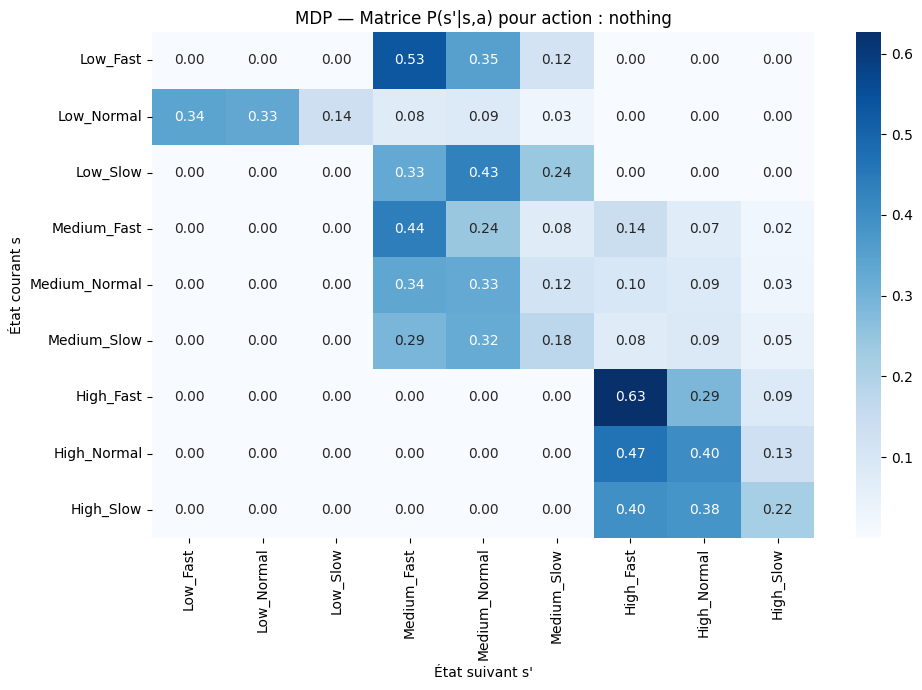

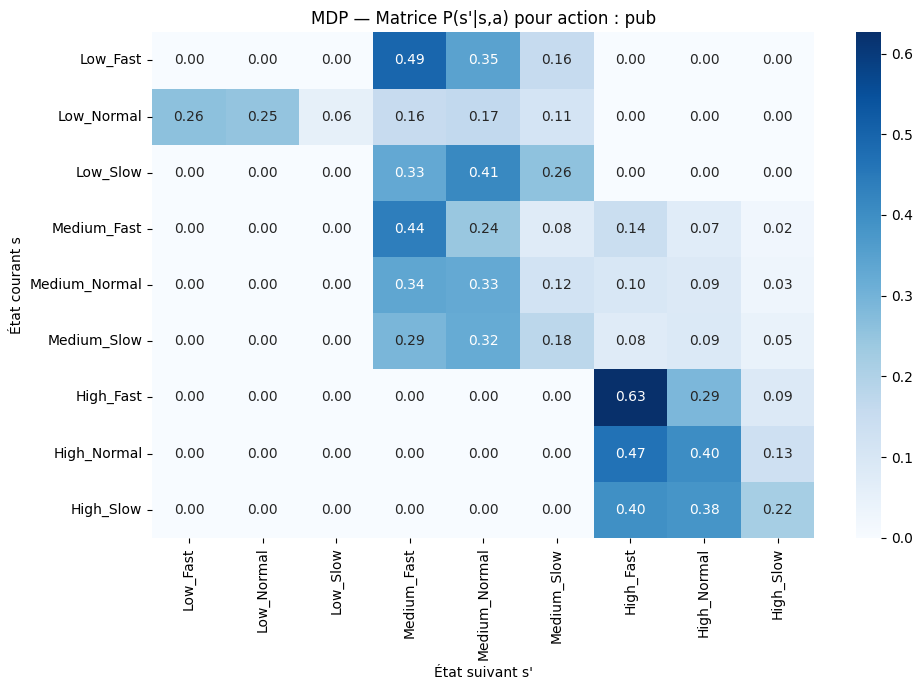

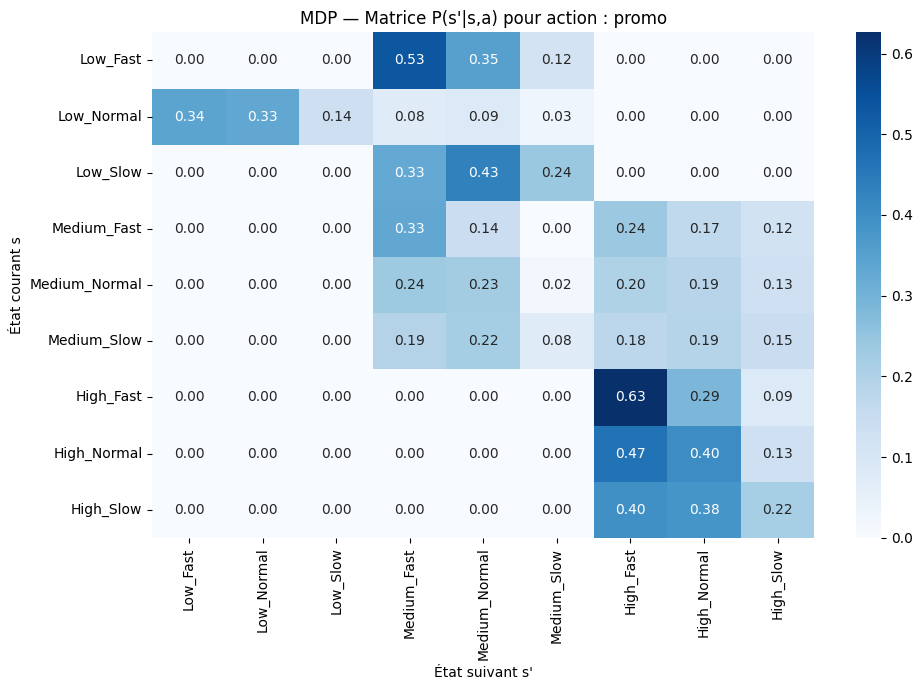

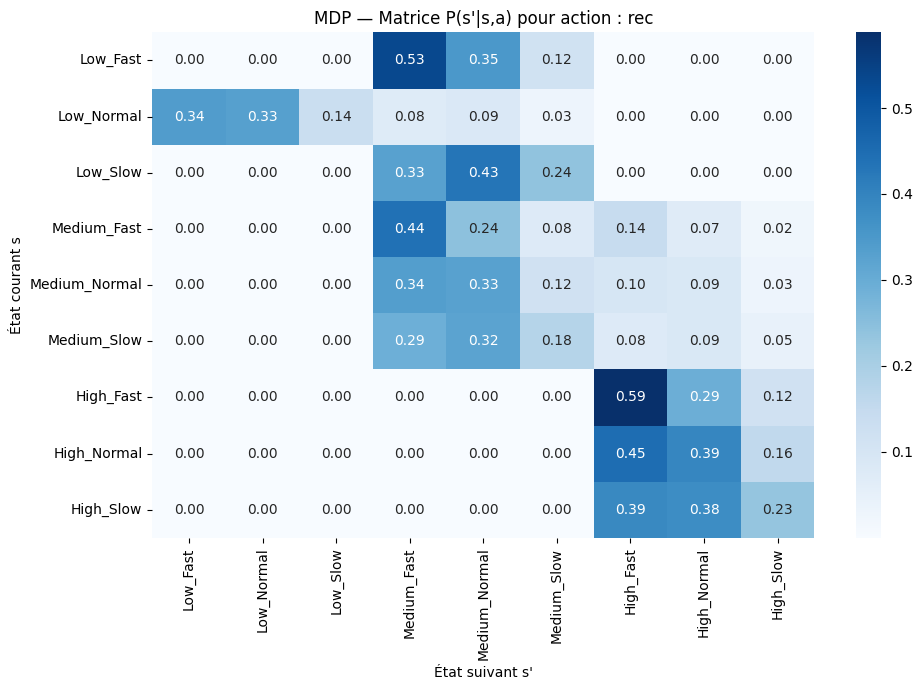

In [34]:
import matplotlib.pyplot as plt
import seaborn as sns

for a in actions:
    plt.figure(figsize=(10, 7))
    sns.heatmap(
        P_actions[a],
        annot=True,
        fmt=".2f",
        cmap="Blues"
    )

    plt.title(f"MDP — Matrice P(s'|s,a) pour action : {a}")
    plt.xlabel("État suivant s'")
    plt.ylabel("État courant s")
    plt.tight_layout()
    plt.show()

La matrice P(s'|s,a) est construite à partir de la matrice naturelle P(s'|s), puis ajustée selon l’effet attendu des actions marketing. L’action nothing conserve la dynamique observée dans les données. L’action pub augmente la probabilité de transition des états Low vers Medium. L’action promo renforce la transition des états Medium vers High. Enfin, l’action rec stabilise les utilisateurs dans les états High afin de favoriser la conversion finale.

## **Howard = Policy Iteration**

**Construire les récompenses R:**

In [35]:
# ============================================================
# Définition des états MDP
# ============================================================

mdp_states = [
    "Low_Fast", "Low_Normal", "Low_Slow",
    "Medium_Fast", "Medium_Normal", "Medium_Slow",
    "High_Fast", "High_Normal", "High_Slow"
]

actions = ["nothing", "pub", "promo", "rec"]

print("États MDP:")
print(mdp_states)

print("\nActions:")
print(actions)

États MDP:
['Low_Fast', 'Low_Normal', 'Low_Slow', 'Medium_Fast', 'Medium_Normal', 'Medium_Slow', 'High_Fast', 'High_Normal', 'High_Slow']

Actions:
['nothing', 'pub', 'promo', 'rec']


In [36]:
# ============================================================
# Rewards R(s,a)
# ============================================================

actions = ["nothing", "pub", "promo", "rec"]

def build_rewards(mdp_states):
    R = pd.DataFrame(
        0.0,
        index=mdp_states,
        columns=actions
    )

    for s in mdp_states:

        # valeur intrinsèque de l'état
        if s.startswith("Low"):
            base_value = 10
        elif s.startswith("Medium"):
            base_value = 30
        elif s.startswith("High"):
            base_value = 80
        else:
            base_value = 0

        # bonus logique selon action adaptée
        R.loc[s, "nothing"] = base_value

        R.loc[s, "pub"] = base_value - 2
        R.loc[s, "promo"] = base_value - 5
        R.loc[s, "rec"] = base_value - 1

        # bonus action correcte
        if s.startswith("Low"):
            R.loc[s, "pub"] += 15

        if s.startswith("Medium"):
            R.loc[s, "promo"] += 20

        if s.startswith("High"):
            R.loc[s, "rec"] += 15

    return R

R = build_rewards(mdp_states)

print("=== Rewards R(s,a) ===")
print(R)

=== Rewards R(s,a) ===
               nothing   pub  promo   rec
Low_Fast          10.0  23.0    5.0   9.0
Low_Normal        10.0  23.0    5.0   9.0
Low_Slow          10.0  23.0    5.0   9.0
Medium_Fast       30.0  28.0   45.0  29.0
Medium_Normal     30.0  28.0   45.0  29.0
Medium_Slow       30.0  28.0   45.0  29.0
High_Fast         80.0  78.0   75.0  94.0
High_Normal       80.0  78.0   75.0  94.0
High_Slow         80.0  78.0   75.0  94.0


In [37]:
# ============================================================
# REBUILD P_data
# ============================================================

import pandas as pd
import numpy as np

mdp_states = [
    "Low_Fast", "Low_Normal", "Low_Slow",
    "Medium_Fast", "Medium_Normal", "Medium_Slow",
    "High_Fast", "High_Normal", "High_Slow"
]

# matrice comptages
P_counts = pd.DataFrame(
    0,
    index=mdp_states,
    columns=mdp_states,
    dtype=float
)

# compter transitions
for seq in state_sequences_mdp:

    for t in range(len(seq) - 1):

        s = seq[t]
        s_next = seq[t + 1]

        if s in mdp_states and s_next in mdp_states:
            P_counts.loc[s, s_next] += 1

# lissage
alpha = 1.0

P_data = (P_counts + alpha).div(
    (P_counts + alpha).sum(axis=1),
    axis=0
)

print("P_data reconstruit ✅")
print(P_data.round(3))

P_data reconstruit ✅
               Low_Fast  Low_Normal  Low_Slow  Medium_Fast  Medium_Normal  \
Low_Fast           0.00       0.000     0.000        0.533          0.350   
Low_Normal         0.34       0.332     0.135        0.075          0.086   
Low_Slow           0.00       0.000     0.000        0.328          0.432   
Medium_Fast        0.00       0.000     0.000        0.439          0.244   
Medium_Normal      0.00       0.000     0.000        0.336          0.327   
Medium_Slow        0.00       0.000     0.000        0.291          0.322   
High_Fast          0.00       0.000     0.000        0.000          0.000   
High_Normal        0.00       0.000     0.000        0.000          0.000   
High_Slow          0.00       0.000     0.000        0.000          0.000   

               Medium_Slow  High_Fast  High_Normal  High_Slow  
Low_Fast             0.117      0.000        0.000      0.000  
Low_Normal           0.031      0.000        0.000      0.000  
Low_Slow        

In [38]:
P_actions = build_P_actions(P_data)

print("P_actions construit ✅")
print(list(P_actions.keys()))

P_actions construit ✅
['nothing', 'pub', 'promo', 'rec']


***Howard / Policy Iteration***

In [39]:
# ============================================================
# HOWARD / POLICY ITERATION
# ============================================================

def policy_evaluation(P_actions, R, policy, gamma=0.9, theta=1e-6):
    V = pd.Series(0.0, index=mdp_states)

    while True:
        delta = 0

        for s in mdp_states:
            a = policy[s]

            value = R.loc[s, a]

            for s_next in mdp_states:
                value += gamma * P_actions[a].loc[s, s_next] * V[s_next]

            delta = max(delta, abs(value - V[s]))
            V[s] = value

        if delta < theta:
            break

    return V


def policy_improvement(P_actions, R, V, gamma=0.9):
    new_policy = {}

    for s in mdp_states:
        best_action = None
        best_value = -np.inf

        for a in actions:
            value = R.loc[s, a]

            for s_next in mdp_states:
                value += gamma * P_actions[a].loc[s, s_next] * V[s_next]

            if value > best_value:
                best_value = value
                best_action = a

        new_policy[s] = best_action

    return new_policy


def policy_iteration(P_actions, R, gamma=0.9, max_iter=100):
    # politique initiale
    policy = {s: "nothing" for s in mdp_states}

    history = []

    for it in range(max_iter):
        V = policy_evaluation(P_actions, R, policy, gamma)
        new_policy = policy_improvement(P_actions, R, V, gamma)

        changes = sum(policy[s] != new_policy[s] for s in mdp_states)

        history.append({
            "iteration": it,
            "changes": changes,
            "mean_value": V.mean()
        })

        print(f"Iteration {it} | changements politique = {changes} | valeur moyenne = {V.mean():.2f}")

        if new_policy == policy:
            print("\nPolicy converged ✅")
            break

        policy = new_policy

    return policy, V, pd.DataFrame(history)

In [40]:
def policy_evaluation(P_actions, R, policy, gamma=0.9, theta=1e-6, max_eval_iter=1000):
    V = pd.Series(0.0, index=mdp_states)

    for _ in range(max_eval_iter):
        delta = 0

        for s in mdp_states:
            a = policy[s]
            value = R.loc[s, a]

            for s_next in mdp_states:
                value += gamma * P_actions[a].loc[s, s_next] * V[s_next]

            delta = max(delta, abs(value - V[s]))
            V[s] = value

        if delta < theta:
            break

    return V

In [41]:
# ============================================================
# POLICY IMPROVEMENT
# ============================================================

def policy_improvement(P_actions, R, V, gamma=0.9):
    new_policy = {}

    for s in mdp_states:
        best_action = None
        best_value = -np.inf

        for a in actions:
            value = R.loc[s, a]

            for s_next in mdp_states:
                value += gamma * P_actions[a].loc[s, s_next] * V[s_next]

            if value > best_value:
                best_value = value
                best_action = a

        new_policy[s] = best_action

    return new_policy


# ============================================================
# HOWARD / POLICY ITERATION
# ============================================================

def policy_iteration(P_actions, R, gamma=0.9, max_iter=100):
    policy = {s: "nothing" for s in mdp_states}
    history = []

    for it in range(max_iter):
        V = policy_evaluation(P_actions, R, policy, gamma)
        new_policy = policy_improvement(P_actions, R, V, gamma)

        changes = sum(policy[s] != new_policy[s] for s in mdp_states)

        history.append({
            "iteration": it,
            "changes": changes,
            "mean_value": V.mean()
        })

        print(f"Iteration {it} | changements = {changes} | valeur moyenne = {V.mean():.2f}")

        if new_policy == policy:
            print("\nPolicy converged ✅")
            break

        policy = new_policy

    return policy, V, pd.DataFrame(history)

In [42]:
policy_howard, V_howard, history_howard = policy_iteration(
    P_actions=P_actions,
    R=R,
    gamma=0.9
)

print("\n=== Politique optimale Howard ===")
for s, a in policy_howard.items():
    print(f"{s} → {a}")

print("\n=== Valeur V(s) ===")
print(V_howard.round(2))

Iteration 0 | changements = 9 | valeur moyenne = 665.71
Iteration 1 | changements = 0 | valeur moyenne = 856.93

Policy converged ✅

=== Politique optimale Howard ===
Low_Fast → pub
Low_Normal → pub
Low_Slow → pub
Medium_Fast → promo
Medium_Normal → promo
Medium_Slow → promo
High_Fast → rec
High_Normal → rec
High_Slow → rec

=== Valeur V(s) ===
Low_Fast         791.39
Low_Normal       750.09
Low_Slow         791.22
Medium_Fast      854.27
Medium_Normal    853.47
Medium_Slow      852.78
High_Fast        939.75
High_Normal      939.74
High_Slow        939.68
dtype: float64


L’algorithme converge en 2 itérations :

Iteration 0 → 9 changements
Iteration 1 → 0 changement

Donc la politique est stable.

Politique optimale obtenue
État utilisateur	Action optimale
Low_Fast / Low_Normal / Low_Slow	pub
Medium_Fast / Medium_Normal / Medium_Slow	promo
High_Fast / High_Normal / High_Slow	rec
Lecture métier
Low → pub : attirer l’attention des utilisateurs en phase d’exploration.
Medium → promo : pousser les utilisateurs engagés vers l’intention d’achat.
High → rec : finaliser la conversion avec une recommandation personnalisée.

#

## **MRP vectoriel :résolution vectorisée de Bellman**

In [46]:
# ======================================================
# MRP / MDP vectorisé — Bellman exact
# Objectif : calculer la valeur business des états utilisateur
# ======================================================

import numpy as np
import pandas as pd

np.random.seed(42)

# ======================================================
# 1. États du parcours utilisateur
# ======================================================

states = ["Browsing", "Engaged", "HighIntent", "Buy", "Exit"]
n_states = len(states)

state_to_idx = {s: i for i, s in enumerate(states)}

# ======================================================
# 2. Simulation du comportement utilisateur
# ======================================================

def simulate_user_session(max_steps=10):
    sequence = []
    current = "Browsing"

    for _ in range(max_steps):

        if current == "Browsing":
            probs = [0.6, 0.3, 0.1, 0.0, 0.0]

        elif current == "Engaged":
            probs = [0.1, 0.5, 0.3, 0.1, 0.0]

        elif current == "HighIntent":
            probs = [0.0, 0.2, 0.5, 0.3, 0.0]

        elif current == "Buy":
            probs = [0.0, 0.0, 0.0, 1.0, 0.0]

        else:  # Exit
            probs = [0.0, 0.0, 0.0, 0.0, 1.0]

        next_state = np.random.choice(states, p=probs)

        sequence.append((current, next_state))

        current = next_state

    return sequence


def generate_data(n_sessions=1000):
    data = []

    for _ in range(n_sessions):
        data.extend(simulate_user_session())

    return data


data = generate_data(n_sessions=1000)

# ======================================================
# 3. Estimation de la matrice de transition P
# ======================================================

P_counts = np.zeros((n_states, n_states))

for s, s_next in data:
    i = state_to_idx[s]
    j = state_to_idx[s_next]

    P_counts[i, j] += 1

P = P_counts.copy()

for i in range(n_states):
    row_sum = P[i].sum()

    if row_sum > 0:
        P[i] = P[i] / row_sum
    else:
        P[i, i] = 1.0

P_df = pd.DataFrame(P, index=states, columns=states)

print("===== Comptages des transitions =====")
display(pd.DataFrame(P_counts, index=states, columns=states))

print("\n===== Matrice de transition estimée P =====")
display(P_df.round(4))

# ======================================================
# 4. Récompenses business R
# ======================================================

R = np.array([0, 2, 5, 20, -10], dtype=float)

R_df = pd.Series(R, index=states, name="Reward")

print("\n===== Reward vector R =====")
display(R_df)

# ======================================================
# 5. Résolution Bellman vectorisée
# V = (I - gamma P)^-1 R
# ======================================================

gamma = 0.9
I = np.eye(n_states)

V = np.linalg.inv(I - gamma * P).dot(R)

V_df = pd.Series(V, index=states, name="Valeur V(s)")

print("\n===== Valeur des états V(s) =====")
display(V_df.round(2))

# ======================================================
# 6. Interprétation des états
# ======================================================

print("\n===== Interprétation =====")

for s, v in V_df.items():

    if s == "Buy":
        interpretation = "État de conversion : revenu maximal"
    elif s == "HighIntent":
        interpretation = "Utilisateur proche de la conversion"
    elif s == "Engaged":
        interpretation = "Utilisateur engagé"
    elif s == "Browsing":
        interpretation = "Utilisateur en exploration"
    else:
        interpretation = "Perte utilisateur / abandon"

    print(f"{s} → {interpretation} | V(s) = {v:.2f}")

# ======================================================
# 7. Analyse business
# ======================================================

best_state = V_df.idxmax()
worst_state = V_df.idxmin()

print("\n===== Analyse business =====")
print(f"État le plus rentable : {best_state}")
print(f"État le plus critique : {worst_state}")

# ======================================================
# 8. Analyse du funnel utilisateur
# ======================================================

print("\n===== Parcours dominant =====")

for i, s in enumerate(states):
    next_state = states[np.argmax(P[i])]
    prob = np.max(P[i])

    print(f"{s} → va le plus souvent vers → {next_state} avec probabilité {prob:.2f}")

===== Comptages des transitions =====


,Browsing,Engaged,HighIntent,Buy,Exit
Browsing,1811.0,876.0,306.0,0.0,0.0
Engaged,227.0,1172.0,663.0,234.0,0.0
HighIntent,0.0,375.0,896.0,473.0,0.0
Buy,0.0,0.0,0.0,2967.0,0.0
Exit,0.0,0.0,0.0,0.0,0.0



===== Matrice de transition estimée P =====


,Browsing,Engaged,HighIntent,Buy,Exit
Browsing,0.6051,0.2927,0.1022,0.0000,0.0
Engaged,0.0989,0.5105,0.2888,0.1019,0.0
HighIntent,0.0000,0.2150,0.5138,0.2712,0.0
Buy,0.0000,0.0000,0.0000,1.0000,0.0
Exit,0.0000,0.0000,0.0000,0.0000,1.0



===== Reward vector R =====


,Reward
Browsing,0.0
Engaged,2.0
HighIntent,5.0
Buy,20.0
Exit,-10.0



===== Valeur des états V(s) =====


,Valeur V(s)
Browsing,100.82
Engaged,123.77
HighIntent,144.66
Buy,200.00
Exit,-100.00



===== Interprétation =====
Browsing → Utilisateur en exploration | V(s) = 100.82
Engaged → Utilisateur engagé | V(s) = 123.77
HighIntent → Utilisateur proche de la conversion | V(s) = 144.66
Buy → État de conversion : revenu maximal | V(s) = 200.00
Exit → Perte utilisateur / abandon | V(s) = -100.00

===== Analyse business =====
État le plus rentable : Buy
État le plus critique : Exit

===== Parcours dominant =====
Browsing → va le plus souvent vers → Browsing avec probabilité 0.61
Engaged → va le plus souvent vers → Engaged avec probabilité 0.51
HighIntent → va le plus souvent vers → HighIntent avec probabilité 0.51
Buy → va le plus souvent vers → Buy avec probabilité 1.00
Exit → va le plus souvent vers → Exit avec probabilité 1.00


la valeur future business de chaque état :

État	Valeur	Sens
Browsing	100.82	utilisateur encore exploratoire, mais il peut évoluer vers achat
Engaged	123.77	plus intéressant que Browsing
HighIntent	144.66	très proche de l’achat
Buy	200.00	état le plus rentable
Exit	-100.00	état de perte
Pourquoi Buy = 200 ?

Car :

Reward Buy = 20
gamma = 0.9
Buy → Buy = 1

Donc :

V(Buy)=20+0.9V(Buy)

donc :

V(Buy)=
1−0.9
20
	​

=200
Pourquoi Exit = -100 ?

Même logique :

V(Exit)=
1−0.9
−10
	​

=−100